In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    root_mean_squared_error,
    r2_score,
)

# Simple Linear Regression using Gradient Descent

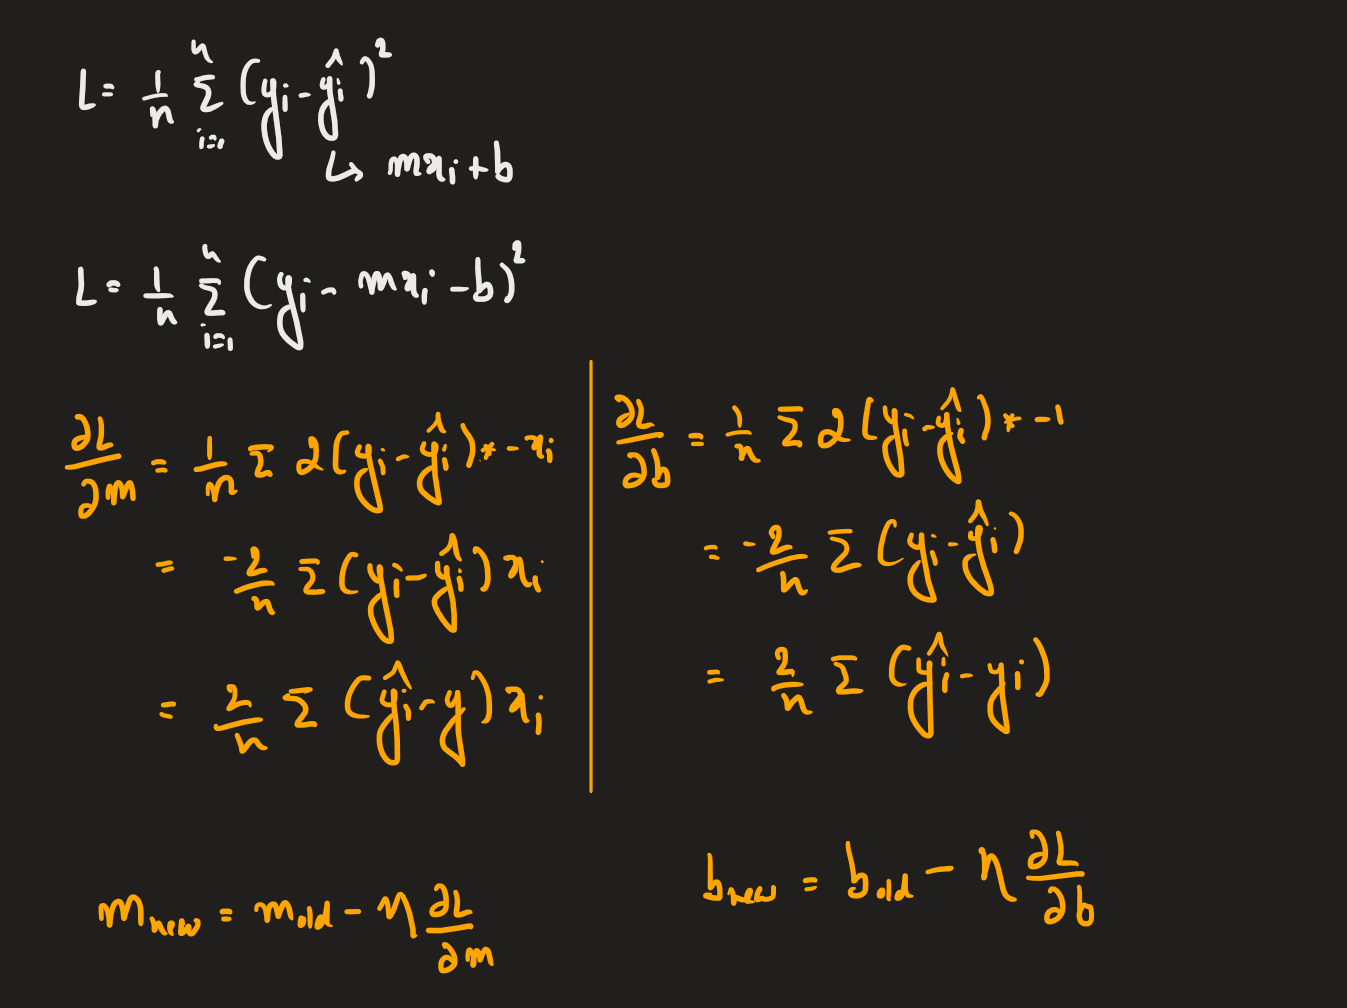

In [ ]:
class SimpleLinearRegressionGD:

    def __init__(self, learning_rate:float=0.01, epochs:int=1000, random_state:int=42):

        if learning_rate <= 0.0 :
            raise ValueError("learning_rate must be positive.")
        
        if epochs < 0 :
            raise ValueError("epochs must be at least 1.")
        
        self.learning_rate = learning_rate
        self.epochs = epochs

        rng = np.random.default_rng(seed=random_state)

        self.coef_ = float(rng.uniform(-1,1))
        self.intercept_ = float(rng.uniform(-1,1))

        self.loss_history_ = []
        self.is_fitted_ = False
    
    def fit(self, X: np.ndarray, y: np.ndarray):

        if X.ndim == 2 and X.shape[1] == 1:
            X = X.ravel()

        if X.ndim != 1:
            raise ValueError("X must contain exactly one feature.")

        if y.ndim != 1:
            raise ValueError("y must be a one-dimensional array.")
        
        if X.shape[0] != y.shape[0]:
            raise ValueError("X and y must have the same number of samples.")
        
        
        n_samples = len(X)
        self.loss_history_ = []

        for _ in range(self.epochs):

            y_hat = self.coef_ * X + self.intercept_

            errors = y_hat - y
            loss = np.mean(errors)
            self.loss_history_.append(loss)
            
            # Calculate gradients
            dL_dm = (2/n_samples) * np.sum(errors * X)
            dL_db = (2/n_samples) * np.sum(errors)

            # Update parameters
            self.coef_ = self.coef_ - self.learning_rate * dL_dm
            self.intercept_ = self.intercept_ - self.learning_rate * dL_db
        
        self.is_fitted_ = True
    
    def predict(self, X: np.ndarray):

        if not self.is_fitted_ :
             raise ValueError("Fit the model before making predictions.")
        
        if X.ndim == 2 and X.shape[1] == 1:
            X = X.ravel()

        if X.ndim != 1:
             raise ValueError("X must contain exactly one feature.")
        
        return self.coef_ * X + self.intercept_

In [3]:
# Generate dummy regression data

X, y = make_regression(
    n_samples=200,
    n_features=1,
    noise=15,
    random_state=42,
)

# Convert X from (n_samples, 1) to (n_samples,).
X = X.ravel()

In [4]:
X.shape, y.shape

((200,), (200,))

In [5]:
# Split the dataset

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

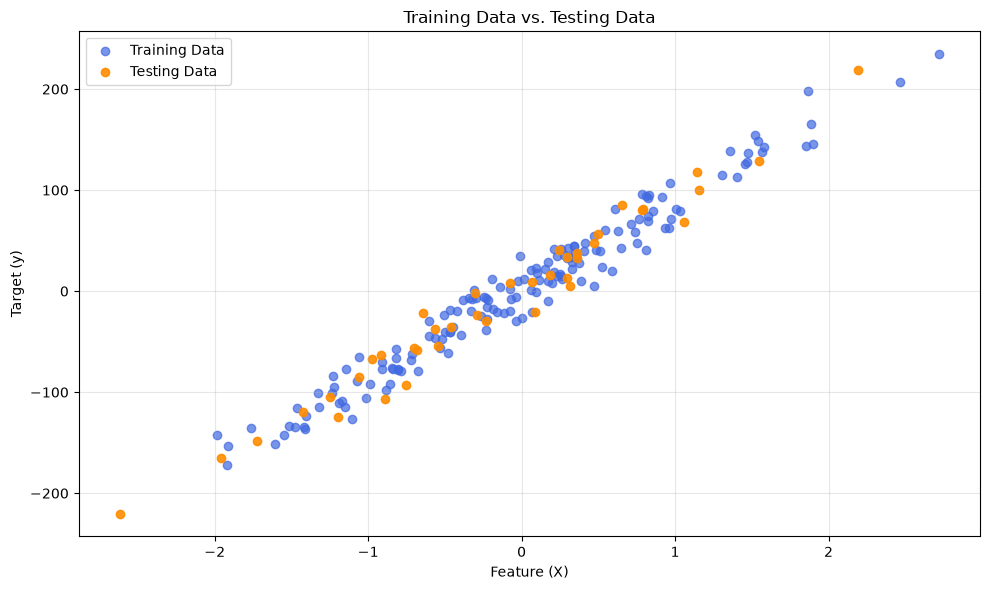

In [6]:
# Visualize the training and testing data

plt.figure(figsize=(10, 6))

plt.scatter(X_train,y_train,color="royalblue",alpha=0.7,label="Training Data",)

plt.scatter(X_test,y_test,color="darkorange",alpha=0.9,label="Testing Data",)

plt.title("Training Data vs. Testing Data")
plt.xlabel("Feature (X)")
plt.ylabel("Target (y)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [9]:
# Train the model

lr = SimpleLinearRegressionGD(
    learning_rate=0.01,
    epochs=1000
)

In [10]:
print(f"Initial coefficient: {lr.coef_:.4f}")
print(f"Initial intercept:   {lr.intercept_:.4f}")

Initial coefficient: 0.5479
Initial intercept:   -0.1222


In [11]:
lr.fit(X_train, y_train)

In [12]:
print(f"Coefficient (slope): {lr.coef_:.4f}")
print(f"Intercept:           {lr.intercept_:.4f}")

Coefficient (slope): 86.8180
Intercept:           1.8346


In [14]:
# Make predictions on the test data

y_pred = lr.predict(X_test)

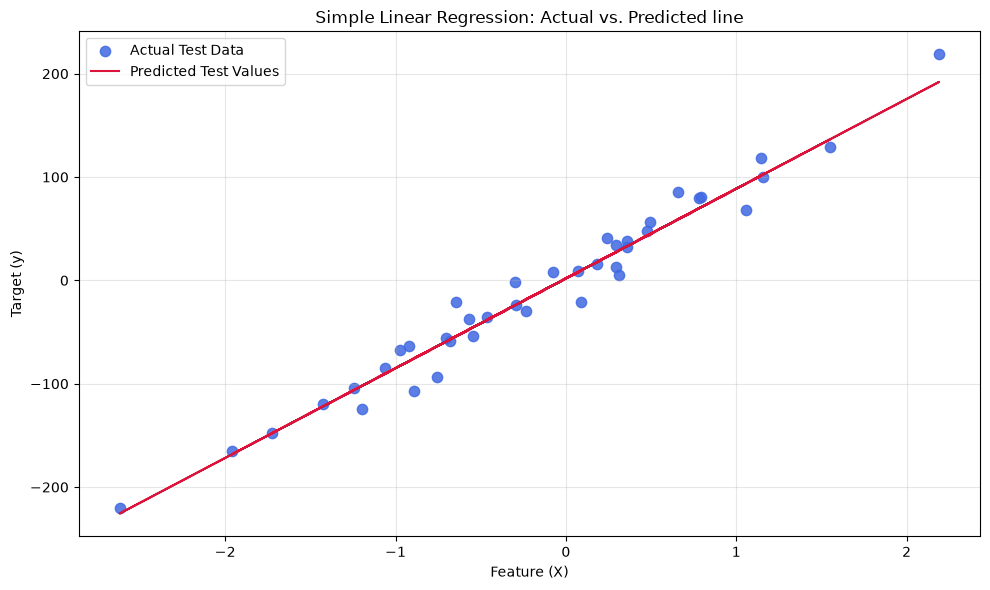

In [16]:
plt.figure(figsize=(10, 6))

plt.scatter(X_test,y_test,color="royalblue",s=55,alpha=0.85,label="Actual Test Data")

plt.plot(X_test,y_pred,color="crimson",label="Predicted Test Values")

plt.title("Simple Linear Regression: Actual vs. Predicted line")
plt.xlabel("Feature (X)")
plt.ylabel("Target (y)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

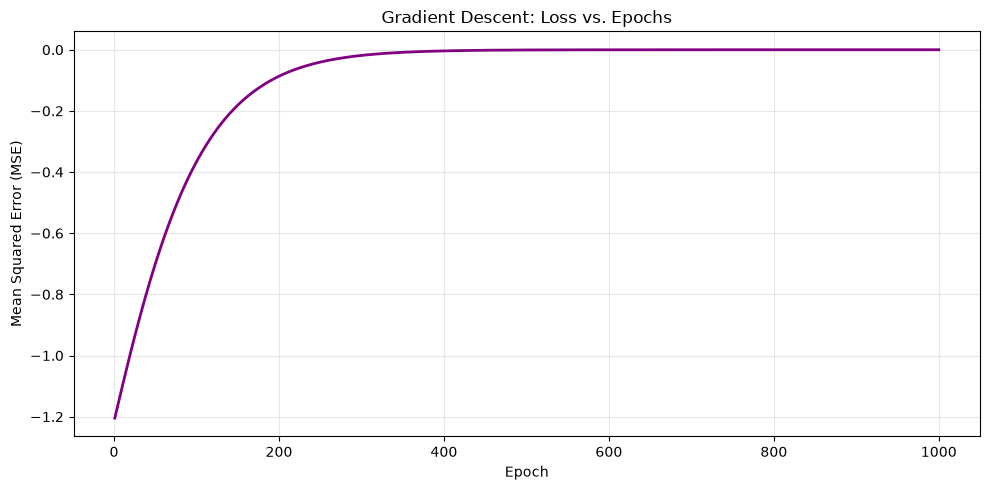

In [18]:
# Visualize the loss during training

plt.figure(figsize=(10, 5))

plt.plot(range(1, lr.epochs + 1), lr.loss_history_, color="purple", linewidth=2)

plt.title("Gradient Descent: Loss vs. Epochs")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [19]:
# Evaluate model performance

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"MAE:  {mae:.4f}")
print(f"MSE:  {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")

MAE:  12.0304
MSE:  246.1218
RMSE: 15.6883
R²:   0.9681
